# Practice effect — distance to cluster medoids

Does practice make players' attempts more prototypical? Every panel reads
`output_data/practice/` (written by `run-practice-distances` and `run-practice-models`);
nothing is refitted here and `mario.scenes` is never opened.

Two measures, kept apart because they answer different questions:

* **`d_own`** — Fréchet distance to the medoid of the attempt's *own* cluster, one
  series per subject × scene × cluster: *when you use this strategy, do you execute it
  more consistently?*
* **`d_nearest_norm`** — distance to the *nearest* medoid (clusters of ≥ 3 members),
  divided by that cluster's spread, one series per subject × scene: *is behaviour
  becoming prototypical of some strategy?* 1.0 = a typical member.

Every measure has a leave-subject-out twin (`_loso`): the medoids are searched among
the *other* subjects, so a late-practice-dominated cluster cannot pull its own
attempts' distances down by construction.

The models are fitted **one subject at a time**: five subjects are too few to
estimate a between-subject variance, so the claim is about these five players,
replicated five times. `d_nearest_norm_loso` is the primary outcome.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUTPUT_DATA_DIR = Path(os.environ["OUTPUT_DATA_DIR"])
PRACTICE_DIR = OUTPUT_DATA_DIR / "practice"

sys.path.insert(0, str(Path("__file__").resolve().parent.parent))
from analysis.practice import load_attempts
from analysis.trace_plots import CLUSTER_COLORS, OTHER_COLOR, SUBJECT_COLORS, N_DIRECT_CLUSTERS

attempts = load_attempts(OUTPUT_DATA_DIR)
curves = pd.read_csv(PRACTICE_DIR / "curves.csv", dtype={"subject": str})
mixed = json.loads((PRACTICE_DIR / "mixed.json").read_text())
switching = json.loads((PRACTICE_DIR / "switching.json").read_text())

UNITS = {"d_own": "Fréchet distance to own medoid (px)",
         "d_nearest_norm": "distance to nearest medoid / its spread"}
RAW, LOSO = CLUSTER_COLORS[0], CLUSTER_COLORS[1]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6})
print(f"{len(attempts)} attempts over {attempts['scene'].nunique()} scenes")

55094 attempts over 300 scenes


## 1. One participant, one scene

The richest subject × scene series. Top: `d_own`, each point coloured by its cluster
(colour slot by whole-scene cluster size, as everywhere else), with a rolling median
for each cluster the subject used >= 10 times, as a visual guide — the fitted curves are in `curves.csv`. Middle:
`d_nearest_norm` over every attempt. Bottom: which cluster each attempt used, so a
strategy switch is visible on its own rather than folded into a distance.
Medoid attempts (distance 0 by definition) are left out.

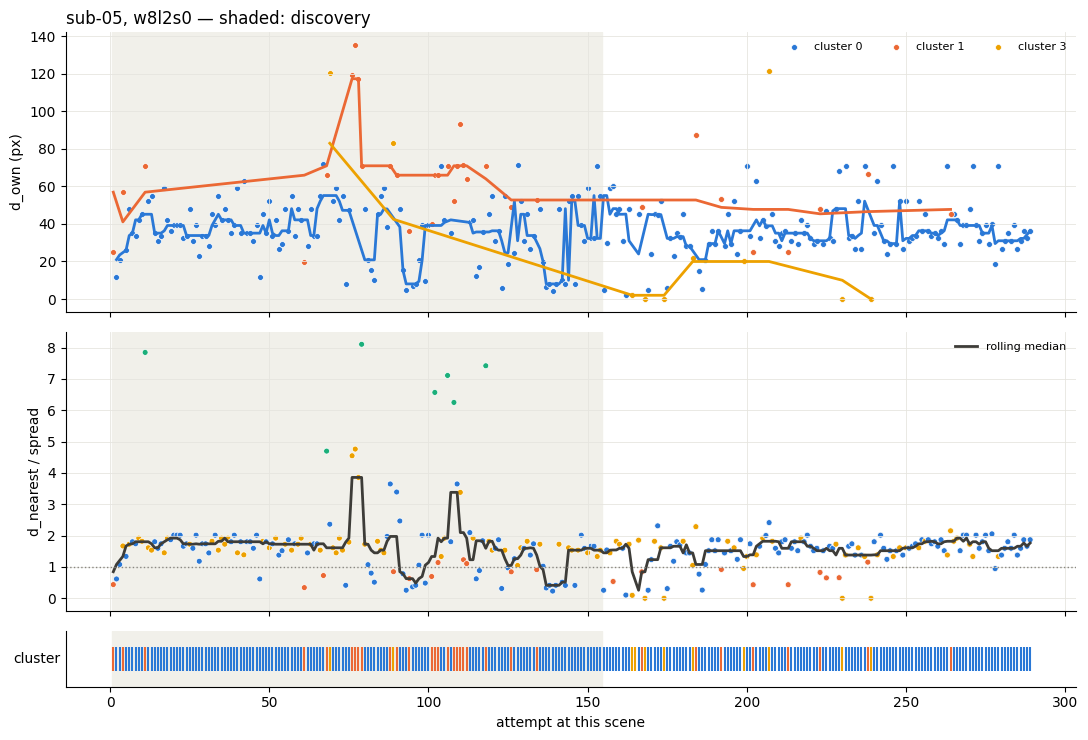

In [2]:
fit = attempts[~attempts["is_medoid"]]
per_cluster = fit.groupby(["scene", "subject", "cluster"]).size()
rich = per_cluster[per_cluster >= 10].groupby(["scene", "subject"]).size()
scene, subject = fit[fit.set_index(["scene", "subject"]).index.isin(rich[rich >= 2].index)] \
    .groupby(["scene", "subject"]).size().idxmax()

scene_df = attempts[attempts["scene"] == scene]
rank = scene_df["cluster"].value_counts().index.tolist()
color = {k: CLUSTER_COLORS[r] if r < N_DIRECT_CLUSTERS else OTHER_COLOR for r, k in enumerate(rank)}
s = scene_df[scene_df["subject"] == subject].sort_values("attempt")
sf = s[~s["is_medoid"]]
boundary = s.loc[s["phase"] == "practice", "attempt"].min()

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [3, 3, 0.6]})
for k, g in sf.groupby("cluster"):
    axes[0].scatter(g["attempt"], g["d_own"], s=18, color=color[k], label=f"cluster {k}",
                    edgecolor="white", linewidth=0.5)
    if len(g) >= 10:   # same floor as the per-series fits; sparser clusters get points only
        axes[0].plot(g["attempt"], g["d_own"].rolling(5, center=True, min_periods=3).median(),
                     color=color[k], linewidth=2)
axes[0].set_ylabel("d_own (px)")
axes[0].legend(ncol=4, fontsize=8, frameon=False, loc="upper right")

axes[1].scatter(sf["attempt"], sf["d_nearest_norm"], s=18, color=[color[k] for k in sf["nearest_cluster"]],
                edgecolor="white", linewidth=0.5)
axes[1].plot(sf["attempt"], sf["d_nearest_norm"].rolling(7, center=True, min_periods=3).median(),
             color="#3d3c38", linewidth=2, label="rolling median")
axes[1].axhline(1.0, color="#898781", linewidth=1, linestyle=":")
axes[1].set_ylabel("d_nearest / spread")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")

axes[2].scatter(s["attempt"], np.zeros(len(s)), marker="|", s=300, color=[color[k] for k in s["cluster"]])
axes[2].set_yticks([]); axes[2].grid(False)
axes[2].set_ylabel("cluster", rotation=0, ha="right", va="center")
axes[2].set_xlabel("attempt at this scene")
for ax in axes:
    if pd.notna(boundary):
        ax.axvspan(s["attempt"].min() - 0.5, boundary - 0.5, color="#f1f0ea", zorder=0)
axes[0].set_title(f"sub-{subject}, {scene} — shaded: discovery", loc="left")
fig.tight_layout()
fig.savefig(PRACTICE_DIR / "figure_practice_example.png", dpi=150)

## 2. The practice effect, subject by subject

One mixed model per subject and measure, on `log(distance)` (attempts at exactly 0 dropped),
with a random intercept
and slope per scene (`d_nearest_norm`) or per scene × cluster (`d_own`). Top: the
practice coefficient with its 95% CI — below zero means attempts moved closer to the
prototypes with practice — raw medoids against leave-subject-out. Bottom: each
subject's fitted curve for the leave-subject-out measure, back-transformed — the
*average scene*, drawn up to the subject's 95th-percentile attempt.

Drawn twice, once per practice form, because the form is a choice the data does not
make for every subject (see the linear-against-log panel below): `log`
(`figure_practice_mixed.png`, coefficient per unit of log(attempt)) and `linear`
(`figure_practice_mixed_linear.png`, coefficient per 10 attempts). The two forms'
coefficients are in different units, so compare them through the curves, not the dots.
If raw and leave-subject-out agree, the decline is not produced by where the medoid
was placed.

**Two transforms.** The primary analysis is on `log(d)`. The original `log1p(d)` analysis
is kept beside it so the switch can be traced: its figures carry a `_log1p` suffix
(`figure_practice_mixed_log1p.png`, `figure_practice_mixed_linear_log1p.png`,
`figure_practice_forms_log1p.png`). `log1p` left the residuals heavily right-skewed;
`log` brings them much closer to normal with the same conclusions — see
`docs/practice_residual_diagnostics_*.png` and `docs/practice_model_decisions.md`.
Slopes are in each transform's own units, so compare the two through the curves.

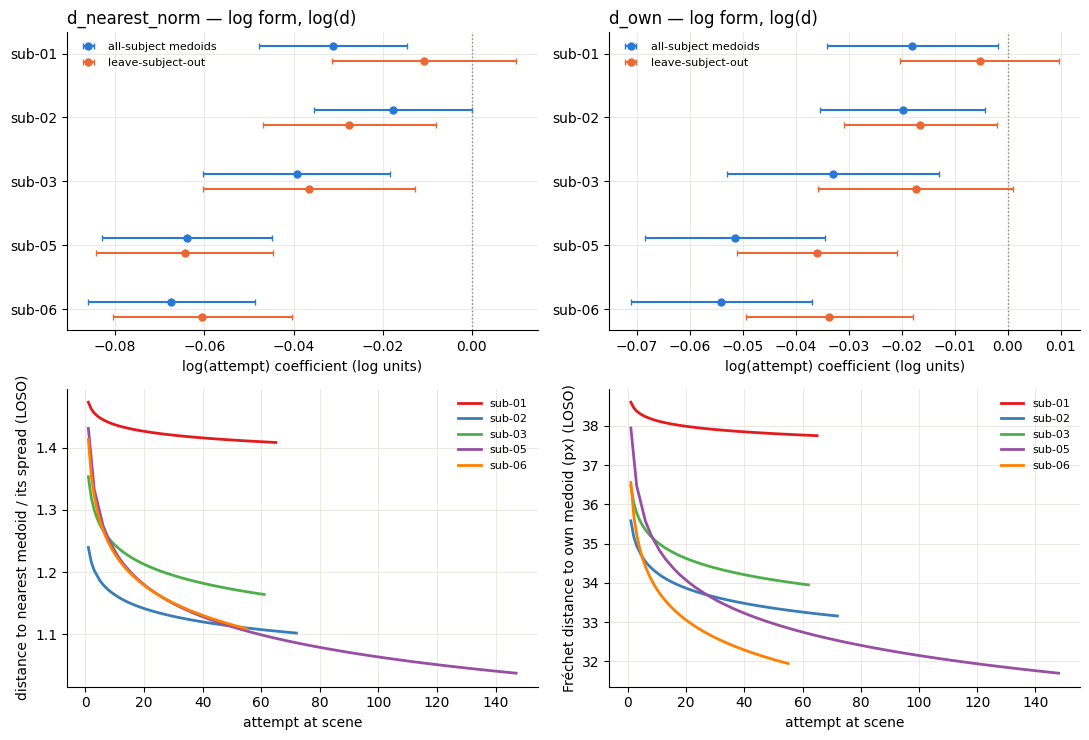

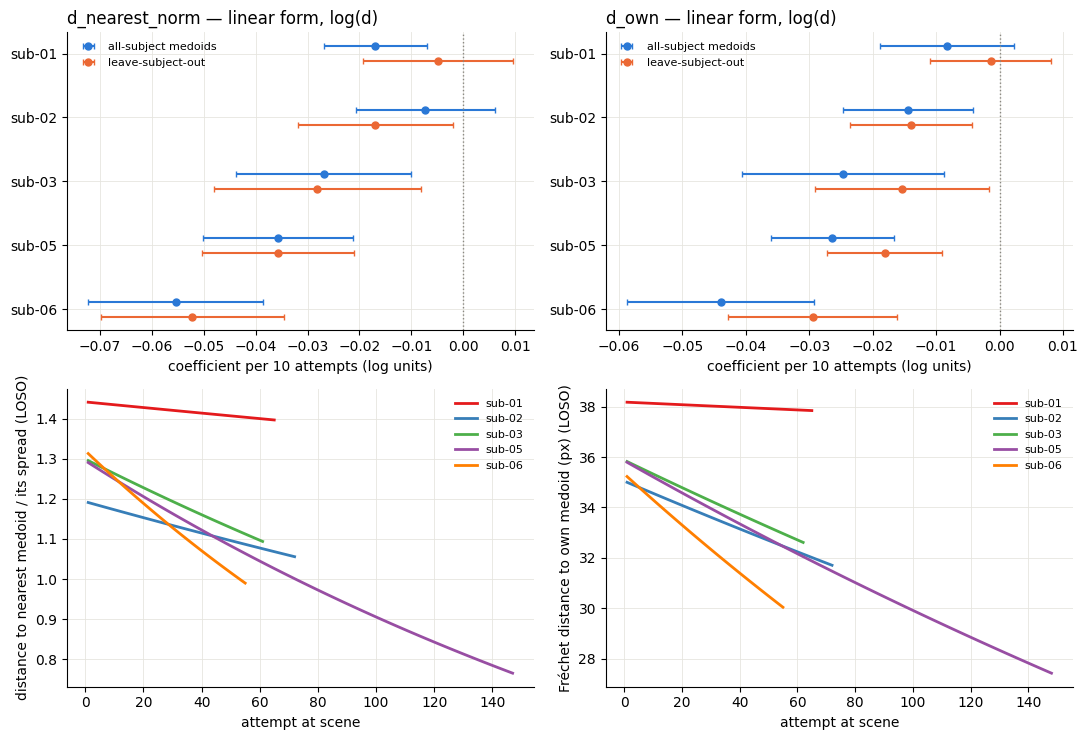

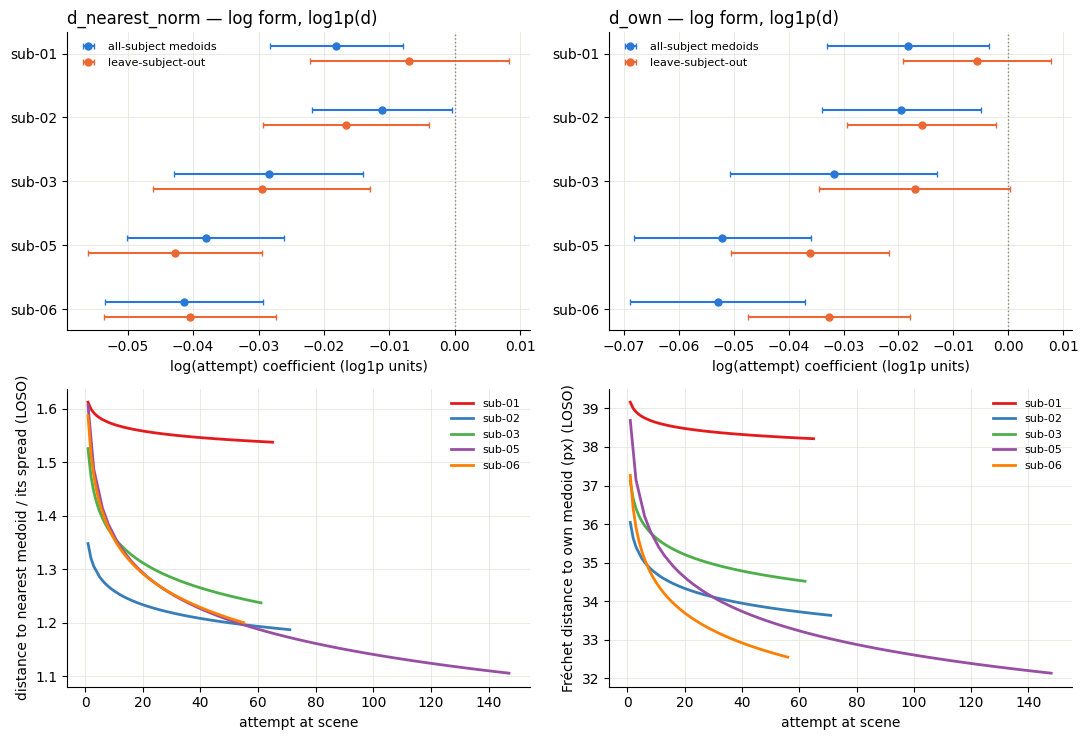

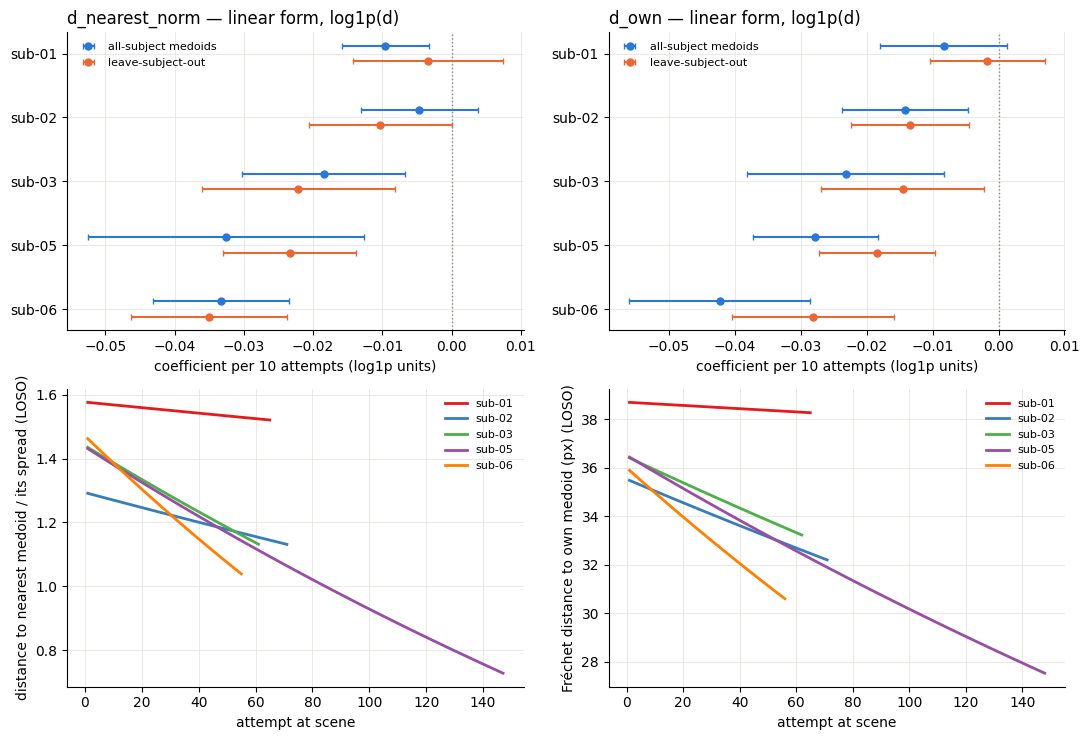

In [3]:
from analysis.practice import TRANSFORMS

PRIMARY_T = mixed["primary_transform"]
INVERSE = {k: v[1] for k, v in TRANSFORMS.items()}


def fits(measure, completed_only=False, transform=PRIMARY_T):
    return {f["subject"]: f for f in mixed["fits"]
            if f["measure"] == measure and f["completed_only"] == completed_only
            and f["transform"] == transform}


SLOPE = {"log": ("logt", "log(attempt) coefficient"),
         "linear": ("t", "coefficient per 10 attempts")}
measures = mixed["measures"]
subjects = mixed["subjects"]


def plot_mixed(form, path, transform=PRIMARY_T):
    term, xlabel = SLOPE[form]
    inv = INVERSE[transform]
    fig, axes = plt.subplots(2, len(measures), figsize=(5.5 * len(measures), 7.5), squeeze=False)
    for j, m in enumerate(measures):
        ax = axes[0, j]
        for off, (col, c, lbl) in zip((-0.12, 0.12), ((m, RAW, "all-subject medoids"),
                                                      (f"{m}_loso", LOSO, "leave-subject-out"))):
            per = fits(col, transform=transform)
            for i, s in enumerate(subjects):
                r = per.get(s, {}).get("forms", {}).get(form, {})
                if "coef" not in r:
                    continue
                b, (lo, hi) = r["coef"][term], r["ci"][term]
                ax.errorbar(b, i + off, xerr=[[b - lo], [hi - b]], fmt="o", color=c,
                            markersize=5, capsize=2, label=lbl if i == 0 else None)
        ax.axvline(0, color="#898781", linewidth=1, linestyle=":")
        ax.set_yticks(range(len(subjects)), [f"sub-{s}" for s in subjects])
        ax.invert_yaxis()
        ax.set_xlabel(f"{xlabel} ({transform} units)")
        ax.set_title(f"{m} — {form} form, {transform}(d)", loc="left")
        ax.legend(frameon=False, fontsize=8)

        ax = axes[1, j]
        for i, s in enumerate(subjects):
            r = fits(f"{m}_loso", transform=transform).get(s, {}).get("forms", {}).get(form, {})
            if "curve" not in r:
                continue
            ax.plot(r["curve"]["attempt"], inv(np.asarray(r["curve"]["y"])), color=SUBJECT_COLORS[i],
                    linewidth=2, label=f"sub-{s}")
        ax.set_xlabel("attempt at scene")
        ax.set_ylabel(UNITS[m] + " (LOSO)")
        ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(PRACTICE_DIR / path, dpi=150)


for transform in mixed["transforms"]:
    suffix = "" if transform == PRIMARY_T else f"_{transform}"
    plot_mixed("log", f"figure_practice_mixed{suffix}.png", transform)
    plot_mixed("linear", f"figure_practice_mixed_linear{suffix}.png", transform)

In [4]:
rows = []
for f in mixed["fits"]:
    for form in ("log", "log_phase"):
        r = f["forms"].get(form, {})
        if "coef" not in r:
            continue
        rows.append({"measure": f["measure"], "transform": f["transform"], "subject": f["subject"],
                     "completed_only": f["completed_only"], "form": form,
                     "coef_logt": r["coef"]["logt"], "ci_low": r["ci"]["logt"][0],
                     "ci_high": r["ci"]["logt"][1], "slope_sd": np.sqrt(r["re"].get("var_slope", np.nan)),
                     "best_form": f["best_form"], "n_obs": f["n_obs"],
                     "n_zero_dropped": f["n_zero_dropped"], "n_groups": f["n_groups"]})
table = pd.DataFrame(rows)
for transform in mixed["transforms"]:
    primary = table[(table["measure"] == mixed["primary"]) & (table["transform"] == transform)
                    & ~table["completed_only"] & (table["form"] == "log")]
    print(f"{mixed['primary']} [{transform}]: log(attempt) CI below zero for "
          f"{(primary['ci_high'] < 0).sum()} of {len(primary)} subjects")
table.round(4)

d_nearest_norm_loso [log]: log(attempt) CI below zero for 4 of 5 subjects
d_nearest_norm_loso [log1p]: log(attempt) CI below zero for 4 of 5 subjects


,measure,transform,subject,completed_only,form,coef_logt,ci_low,ci_high,slope_sd,best_form,n_obs,n_zero_dropped,n_groups
0,d_nearest_norm,log,01,False,log,-0.0312,-0.0478,-0.0146,0.0939,log,12590,48,290
1,d_nearest_norm,log,01,False,log_phase,-0.0387,-0.0620,-0.0154,0.0940,log,12590,48,290
2,d_nearest_norm,log,02,False,log,-0.0177,-0.0353,-0.0001,0.0928,log,10985,77,296
3,d_nearest_norm,log,02,False,log_phase,-0.0282,-0.0516,-0.0047,0.0928,log,10985,77,296
4,d_nearest_norm,log,03,False,log,-0.0393,-0.0603,-0.0183,0.1204,linear,9131,89,299
...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,d_own_loso,log1p,03,True,log_phase,-0.0035,-0.0277,0.0206,0.1390,linear,8400,0,1053
156,d_own_loso,log1p,05,True,log,-0.0364,-0.0514,-0.0214,0.0802,quadratic,9969,0,1122
157,d_own_loso,log1p,05,True,log_phase,-0.0374,-0.0573,-0.0174,0.0803,quadratic,9969,0,1122
158,d_own_loso,log1p,06,True,log,-0.0335,-0.0481,-0.0190,0.0762,quadratic,8424,0,984


### Linear against log, per subject

The panels above draw every subject in the `log` form so the five are compared on one
shape — but that is a choice, not what each subject's data prefers. Here both forms
are drawn for the primary measure (`d_nearest_norm_loso`, all attempts), back-transformed
to the distance ratio, with the AIC difference in each title: **linear − log**, so a
positive number means log fits better and a negative one that linear does. Differences
under ~2 are a tie. Both curves are the *average scene* (scene adjustments set to 0),
drawn up to the subject's 95th-percentile attempt. Drawn per transform:
`figure_practice_forms.png` for `log`, `figure_practice_forms_log1p.png` for `log1p`.

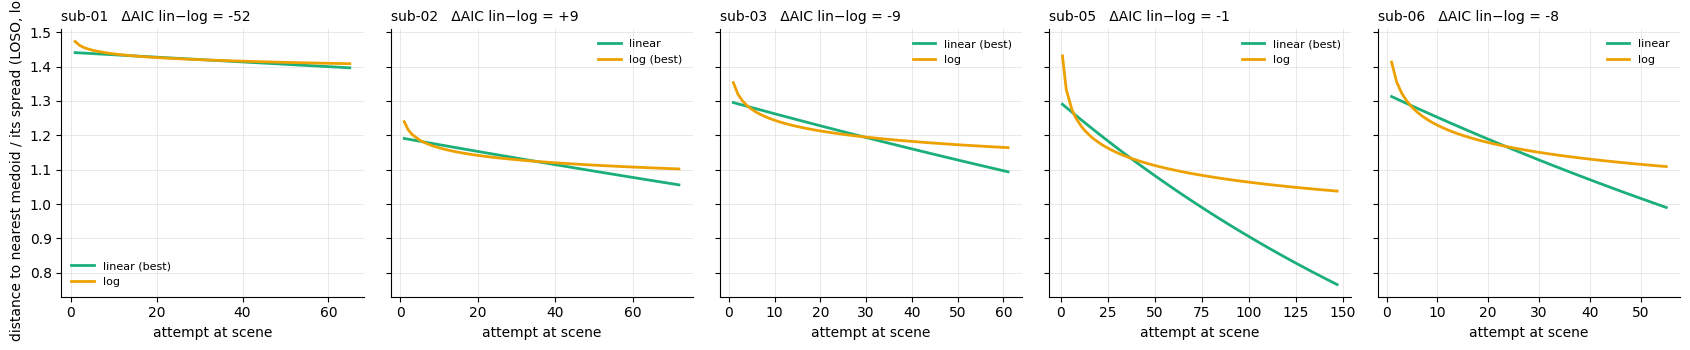

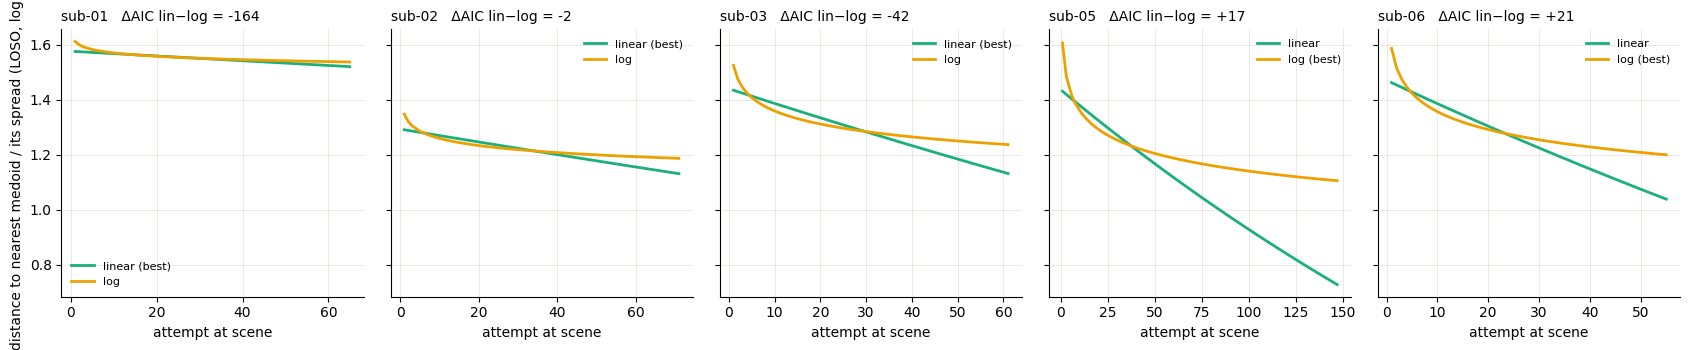

In [5]:
FORM_COLORS = {"linear": CLUSTER_COLORS[2], "log": CLUSTER_COLORS[3]}
for transform in mixed["transforms"]:
    per = fits(mixed["primary"], transform=transform)
    inv = INVERSE[transform]
    fig, axes = plt.subplots(1, len(subjects), figsize=(3.4 * len(subjects), 3.6), sharey=True)
    for ax, s in zip(np.atleast_1d(axes), subjects):
        forms = per[s]["forms"]
        for form, c in FORM_COLORS.items():
            r = forms.get(form, {})
            if "curve" not in r:
                continue
            ax.plot(r["curve"]["attempt"], inv(np.asarray(r["curve"]["y"])), color=c, linewidth=2,
                    label=f"{form}" + (" (best)" if per[s]["best_form"] == form else ""))
        diff = forms["linear"]["aic"] - forms["log"]["aic"]
        ax.set_title(f"sub-{s}   ΔAIC lin−log = {diff:+.0f}", loc="left", fontsize=10)
        ax.set_xlabel("attempt at scene")
        ax.legend(frameon=False, fontsize=8)
    np.atleast_1d(axes)[0].set_ylabel(UNITS["d_nearest_norm"] + f" (LOSO, {transform})")
    fig.tight_layout()
    suffix = "" if transform == PRIMARY_T else f"_{transform}"
    fig.savefig(PRACTICE_DIR / f"figure_practice_forms{suffix}.png", dpi=150)

### Random-effect structure: scenes nested in levels

The main model gives each scene a correlated random intercept and slope and assumes scenes
are independent — but a level's scenes are played back to back. Two alternatives are fitted
beside it, `log` form only, in `nested.json`: `level_scene` adds a random intercept and
slope per **level** with the scene effects nested inside, and `scene_uncorr` is the
scene-only model with the same restriction statsmodels imposes on nesting (no scene
intercept-slope correlation), so `level_scene` against `scene_uncorr` isolates what levels
add. Left: the practice slope with its 95% CI under each structure, for the primary
measure, all attempts. Right: the AIC difference against the main model — below zero fits
better. The main model keeps the scene correlation the nested one cannot have, so neither
alternative is a strict improvement on it; the model that has both needs lme4.

,transform,subject,structure,b,ci_low,ci_high,aic
0,log,01,scene,-0.0108,-0.0314,0.0099,25692.0487
1,log,02,scene,-0.0275,-0.0469,-0.0080,21926.0965
2,log,03,scene,-0.0366,-0.0604,-0.0129,19734.0593
3,log,05,scene,-0.0644,-0.0842,-0.0446,24641.9583
4,log,06,scene,-0.0604,-0.0804,-0.0404,18424.7539
5,log,01,scene_uncorr,-0.0095,-0.0261,0.0072,25781.6608
6,log,02,scene_uncorr,-0.0258,-0.0410,-0.0106,21970.8983
7,log,03,scene_uncorr,-0.0369,-0.0546,-0.0192,19849.7567
8,log,05,scene_uncorr,-0.0580,-0.0747,-0.0412,24680.8544
9,log,06,scene_uncorr,-0.0574,-0.0747,-0.0401,18453.1437


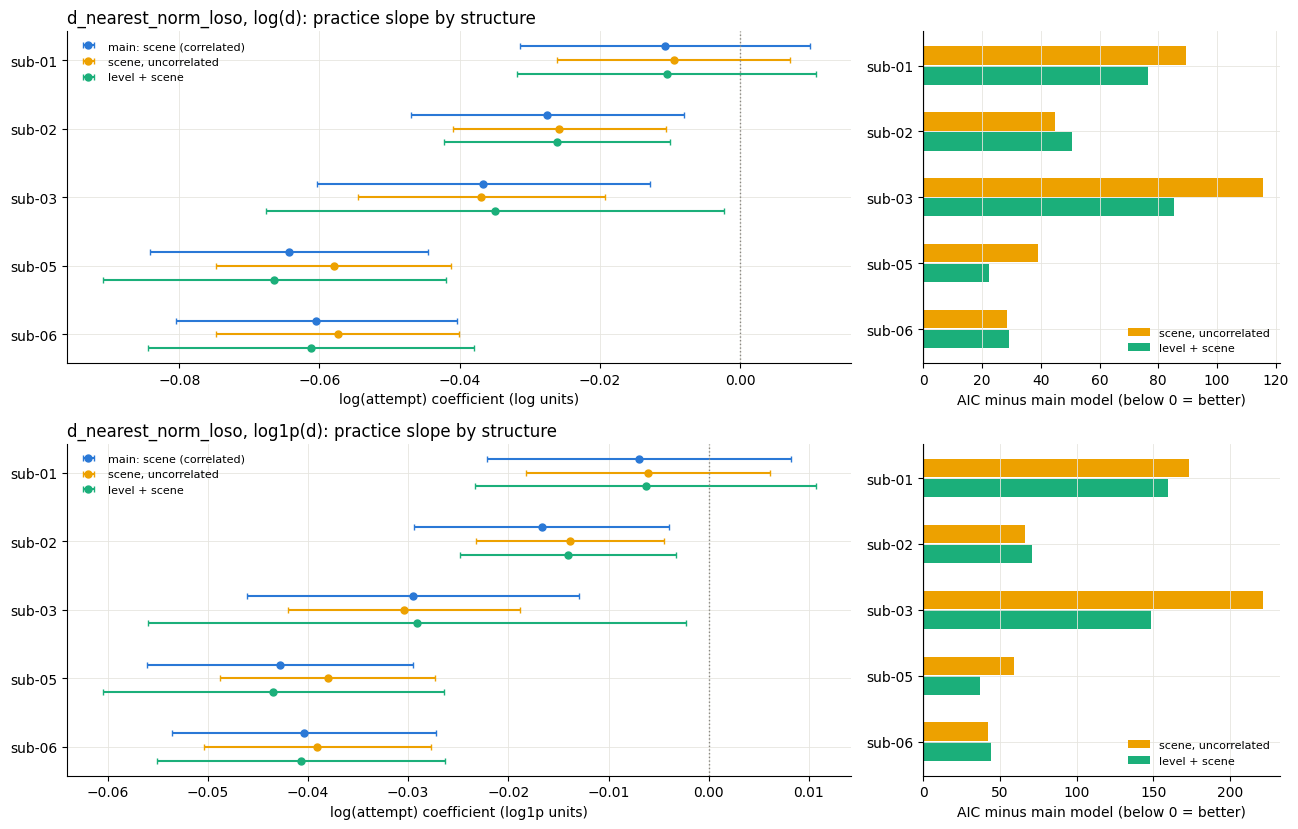

In [6]:
nested = json.loads((PRACTICE_DIR / "nested.json").read_text())
STRUCT = {"scene": ("main: scene (correlated)", CLUSTER_COLORS[0]),
          "scene_uncorr": ("scene, uncorrelated", CLUSTER_COLORS[3]),
          "level_scene": ("level + scene", CLUSTER_COLORS[2])}


def structure_fits(transform):
    out = {("scene", s): f["forms"]["log"] for s, f in fits(mixed["primary"], transform=transform).items()}
    for f in nested["fits"]:
        if (f["measure"] == mixed["primary"] and f["transform"] == transform
                and not f["completed_only"] and "coef" in f):
            out[(f["structure"], f["subject"])] = f
    return out


fig, axes = plt.subplots(len(mixed["transforms"]), 2, figsize=(13, 4.2 * len(mixed["transforms"])),
                         squeeze=False, gridspec_kw={"width_ratios": [2.2, 1]})
rows = []
for k, transform in enumerate(mixed["transforms"]):
    sf = structure_fits(transform)
    ax, axa = axes[k]
    for off, st in zip((-0.2, 0, 0.2), STRUCT):
        label, c = STRUCT[st]
        for i, s in enumerate(subjects):
            r = sf.get((st, s))
            if r is None:
                continue
            b, (lo, hi) = r["coef"]["logt"], r["ci"]["logt"]
            ax.errorbar(b, i + off, xerr=[[b - lo], [hi - b]], fmt="o", color=c, ms=5, capsize=2,
                        label=label if i == 0 else None)
            rows.append({"transform": transform, "subject": s, "structure": st, "b": b,
                         "ci_low": lo, "ci_high": hi, "aic": r["aic"]})
    ax.axvline(0, color="#898781", lw=1, ls=":")
    ax.set_yticks(range(len(subjects)), [f"sub-{s}" for s in subjects])
    ax.invert_yaxis()
    ax.set_xlabel(f"log(attempt) coefficient ({transform} units)")
    ax.set_title(f"{mixed['primary']}, {transform}(d): practice slope by structure", loc="left")
    ax.legend(frameon=False, fontsize=8)
    t = pd.DataFrame([r for r in rows if r["transform"] == transform])
    a = t.pivot(index="subject", columns="structure", values="aic").loc[subjects]
    for off, st in zip((-0.15, 0.15), ("scene_uncorr", "level_scene")):
        axa.barh(np.arange(len(subjects)) + off, a[st] - a["scene"], height=0.28,
                 color=STRUCT[st][1], label=STRUCT[st][0])
    axa.axvline(0, color="k", lw=0.8)
    axa.set_yticks(range(len(subjects)), [f"sub-{s}" for s in subjects])
    axa.invert_yaxis()
    axa.set_xlabel("AIC minus main model (below 0 = better)")
    axa.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(PRACTICE_DIR / "figure_practice_structures.png", dpi=150)
pd.DataFrame(rows).round(4)

## 3. Which curve shape, series by series

For every series with ≥ 10 attempts: which of linear / quadratic / power / exponential
has the lowest AICc, and whether the best curve ends lower than it started. The
`change` column is in transformed units, so it is comparable across curve shapes.
Drawn for the primary transform; `curves.csv` holds both.

series  median_n   fell  median_change
transform measure                                                    
log       d_nearest_norm         1403      32.0  0.612         -0.123
          d_nearest_norm_loso    1411      33.0  0.605         -0.108
          d_own                  1584      18.0  0.559         -0.064
          d_own_loso             1603      18.0  0.524         -0.024
log1p     d_nearest_norm         1403      32.0  0.629         -0.073
          d_nearest_norm_loso    1411      34.0  0.619         -0.067
          d_own                  1598      18.0  0.566         -0.066
          d_own_loso             1615      18.0  0.533         -0.030

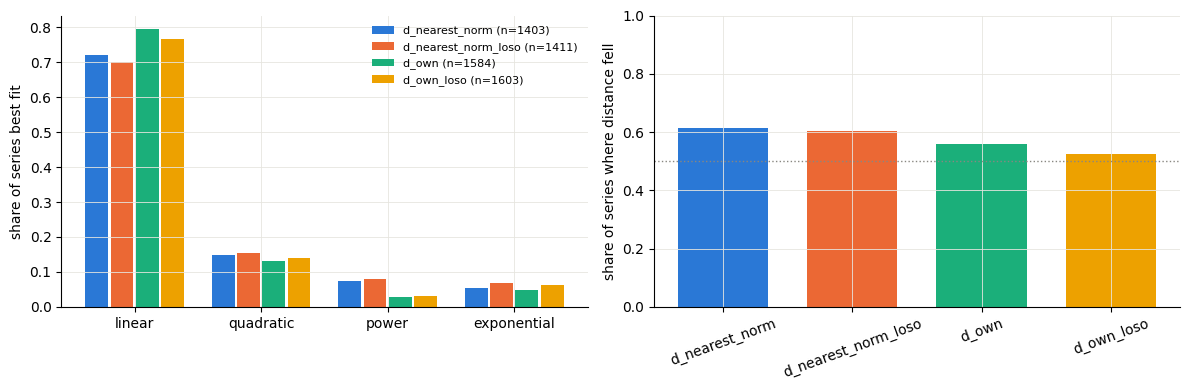

In [7]:
models = ["linear", "quadratic", "power", "exponential"]
measure_cols = [c for m in measures for c in (m, f"{m}_loso")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
width = 0.8 / len(measure_cols)
palette = CLUSTER_COLORS[:len(measure_cols)]
for i, (col, c) in enumerate(zip(measure_cols, palette)):
    sub = curves[(curves["measure"] == col) & (curves["transform"] == PRIMARY_T)]
    share = sub["best"].value_counts(normalize=True).reindex(models, fill_value=0)
    axes[0].bar(np.arange(len(models)) + (i - (len(measure_cols) - 1) / 2) * width, share,
                width=width * 0.9, color=c, label=f"{col} (n={len(sub)})")
    axes[1].bar(i, (sub["change"] < 0).mean(), color=c, width=0.7)
axes[0].set_xticks(range(len(models)), models)
axes[0].set_ylabel("share of series best fit")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xticks(range(len(measure_cols)), measure_cols, rotation=20)
axes[1].axhline(0.5, color="#898781", linestyle=":", linewidth=1)
axes[1].set_ylabel("share of series where distance fell")
axes[1].set_ylim(0, 1)
fig.tight_layout()
fig.savefig(PRACTICE_DIR / "figure_practice_curves.png", dpi=150)
curves.groupby(["transform", "measure"]).agg(series=("n", "size"), median_n=("n", "median"),
                              fell=("change", lambda x: (x < 0).mean()),
                              median_change=("change", "median")).round(3)

## 4. Does strategy choice settle?

Share of attempts using a different cluster than the subject's previous attempt at the
same scene, pooled over scenes in bins of attempts. The trend is a logistic GLM on
`log(attempt)` with errors clustered by subject × scene.

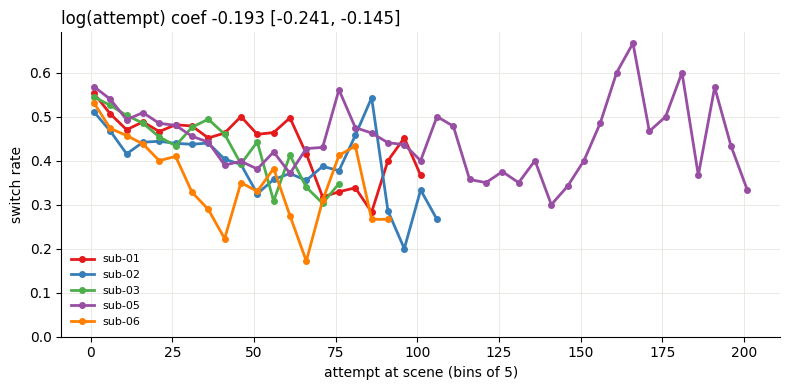

In [8]:
b = pd.DataFrame(switching["binned"])
b = b[b["n"] >= 30]
fig, ax = plt.subplots(figsize=(8, 4))
for i, (subj, g) in enumerate(b.groupby("subject")):
    ax.plot(g["bin"], g["rate"], color=SUBJECT_COLORS[i], linewidth=2, marker="o", markersize=4,
            label=f"sub-{subj}")
ax.set_xlabel(f"attempt at scene (bins of {switching['bin_width']})")
ax.set_ylabel("switch rate")
ax.set_ylim(0, None)
ax.legend(frameon=False, fontsize=8)
t = switching["trend"]
ax.set_title(f"log(attempt) coef {t['coef_logt']:.3f} [{t['ci'][0]:.3f}, {t['ci'][1]:.3f}]", loc="left")
fig.tight_layout()
fig.savefig(PRACTICE_DIR / "figure_practice_switching.png", dpi=150)